
# Uncertainty-Aware Corrosion Risk Assessment for FPSO Pipelines

This notebook implements:
- Baseline: Distance-based uncertainty
- Advanced: Bayesian GMM & Ensemble uncertainty
- Comparative evaluation

Dataset: PRDS_Merged_Docs.xlsx


In [108]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("PRDS_files/PRDS_Merged_Docs_Normalized.xlsx")
df.head()


,filename,date,prdsNumber,lineLocation,lineId,nominalPipeSize,originalWallThickness,pipeSchedule,pipeMaterial,pipeGrade,...,Product,axialLength,circumferentialWidth,damageLocation,remainingWallThickness,corrosionPercentage,internalCorrosionRate,isLeaking,temporaryRepair,additionalNotes
0,PRDS_1534_24-CM-A2-138-031,2023-06-08,PRDS_1534,M5P,24-CM-A2-138-031,"20""",9.53,STD,carbon steel,A106 GR-B,...,Seawater,900.0,400.0,external,2.8,70.6,NaN,0.0,1.0,Significant localized material loss on the pip...
1,PRDS_TR01628_03-UW-M-004-106,2023-12-02,PRDS_1628,KNK- module 5P,03-UW-M-004-106,"2""",5.54,XS,carbon steel,NaN,...,RO Water,NaN,NaN,internal,0.0,NaN,NaN,1.0,0.0,Internal corrosion noted on seam at flange con...
2,PRDS_TR01503_04-DC-B2-10501-002,2023-05-07,PRDS_1503,MV21 - M2P,04-DC-B2-10501-002,"4""",6.02,40,carbon steel,ASTM A106 GR B,...,Closed Drain - HC,80.0,50.0,external,1.0,NaN,NaN,0.0,0.0,NaN
3,PRDS_TR01515_04-DC-B2-10501-005,2023-05-13,PRDS_1515,MV21 - M2P,04-DC-B2-10501-005,"4""",6.02,40,carbon steel,ASTM A106 GR B,...,Closed Drain - HC,NaN,NaN,external,1.1,NaN,NaN,0.0,0.0,NaN
4,PRDS_1546_02-DC-A2-137-002,2023-06-24,PRDS_1546,Module 5S,02-DC-A2-137-002,"2""",5.54,NaN,carbon steel,NaN,...,Closed Drain - HC,60.0,60.0,external,1.4,NaN,NaN,0.0,0.0,NO scales to be removed during repair


# Visualising the Data 

In [187]:
exclude_products = [
    "IG Vent", "Service Water", "Utility Air", "Hydrocarbon liquid",
    "Hydrocarbon", "Diesel oil", "Cond. Water", "Utility water",
    "Deluge system", "LP fuel Gas", "Air Vent", "Diesel fuel",
    "Compressed Air", "Water injection", "Marine Diesel oil",
    "Vent air", "Methanol", "Deluge water", "Foam water", "Service Air"
    "Hydraulic Fluid", "Deck Foam", "Hydrocholorite", "Diesel Fuel",
    "Drain Water", "Instrument Air", "Glycol", "Dilution Water", "LP Fuel Gas",
    "Vent Air", "Utility Water", "Service Air",
    "Deluge Water", "Diesel Fuel"
]

In [188]:
df_filtered = df[~df['Product'].isin(exclude_products)]

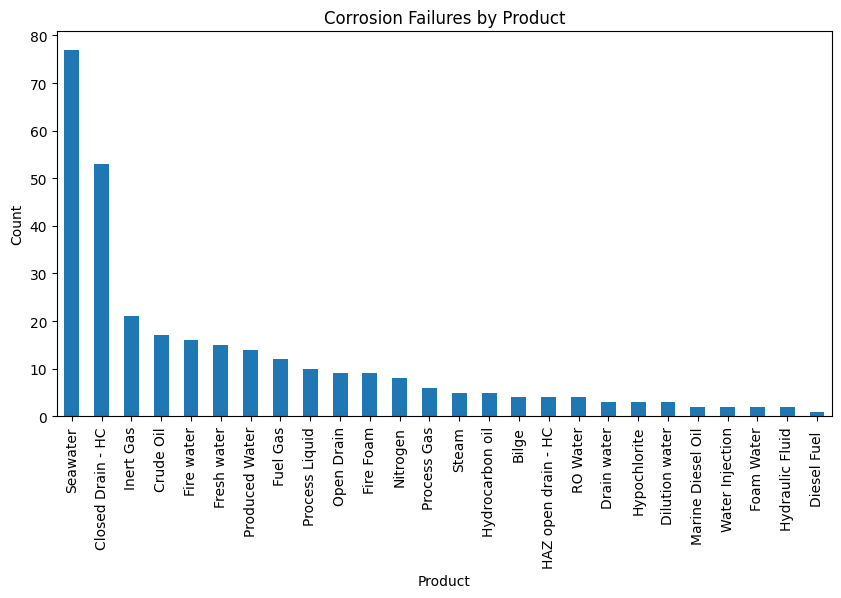

In [189]:
df_filtered['Product'].value_counts().plot(kind='bar',figsize=(10,5))
plt.title("Corrosion Failures by Product")
plt.xlabel("Product")
plt.ylabel("Count")
plt.show()

## Feature Engineering

### Exposure Time (Assumption of the start as 2010)

In [183]:
df['date'] = pd.to_datetime(df['date'])

df['Exposure_Years'] = df['date'].dt.year - 2010
df = df[df['Exposure_Years'] > 0]  # remove invalid

### Corrosion Rate

In [184]:
df['Corrosion_Rate'] = (
    df['originalWallThickness'] - df['remainingWallThickness']
) / df['Exposure_Years']

### Remaining Useful Life (RUL)

In [185]:
CRITICAL_THICKNESS = 1.0  # engineering assumption

df['RUL'] = (
    df['remainingWallThickness'] - CRITICAL_THICKNESS
) / df['Corrosion_Rate']

### Degradation Over Time

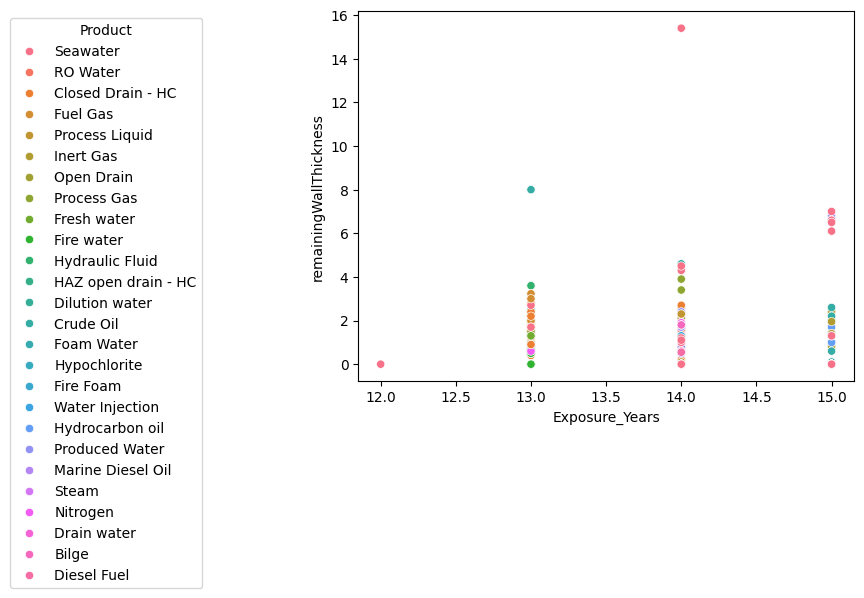

In [192]:
sns.scatterplot(
    data=df_filtered,
    x="Exposure_Years",
    y="remainingWallThickness",
    hue="Product"
)
plt.legend(
    title="Product",
    bbox_to_anchor=(-0.3, 1),  # move to left
    loc='upper right'
)

# Machine Learning Model (Regression)

In [94]:
df_original = df.copy()

In [95]:
df = pd.get_dummies(df, columns=["Product"], drop_first=True)

### Features

In [96]:
features = [
    "Exposure_Years",
    "maxOperatingTemperature",
    "maxOperatingPressure"
] + [col for col in df.columns if "Product_" in col]

X = df[features]

### Model 1: Predict Corrosion Rate

In [97]:
from sklearn.ensemble import RandomForestRegressor

model_cr = RandomForestRegressor(n_estimators=200, random_state=42)
model_cr.fit(X, df['Corrosion_Rate'])

df['Pred_CR'] = model_cr.predict(X)

### Model 2: Predict RUL

In [98]:
model_rul = RandomForestRegressor(n_estimators=200, random_state=42)
model_rul.fit(X, df['RUL'])

df['Pred_RUL'] = model_rul.predict(X)

## Uncertainty Quantification

In [99]:
import numpy as np

preds = []

for i in range(50):
    m = RandomForestRegressor(n_estimators=100)
    m.fit(X, df['RUL'])
    preds.append(m.predict(X))

preds = np.array(preds)

df['RUL_std'] = preds.std(axis=0)
df['Confidence'] = 1 / (1 + df['RUL_std'])

### Risk Score

In [100]:
df['Risk_Score'] = (1 / df['Pred_RUL']) * df['RUL_std']

In [101]:
df_original['Risk_Score'] = df['Risk_Score']

# Final Visualisations

### Risk by Product

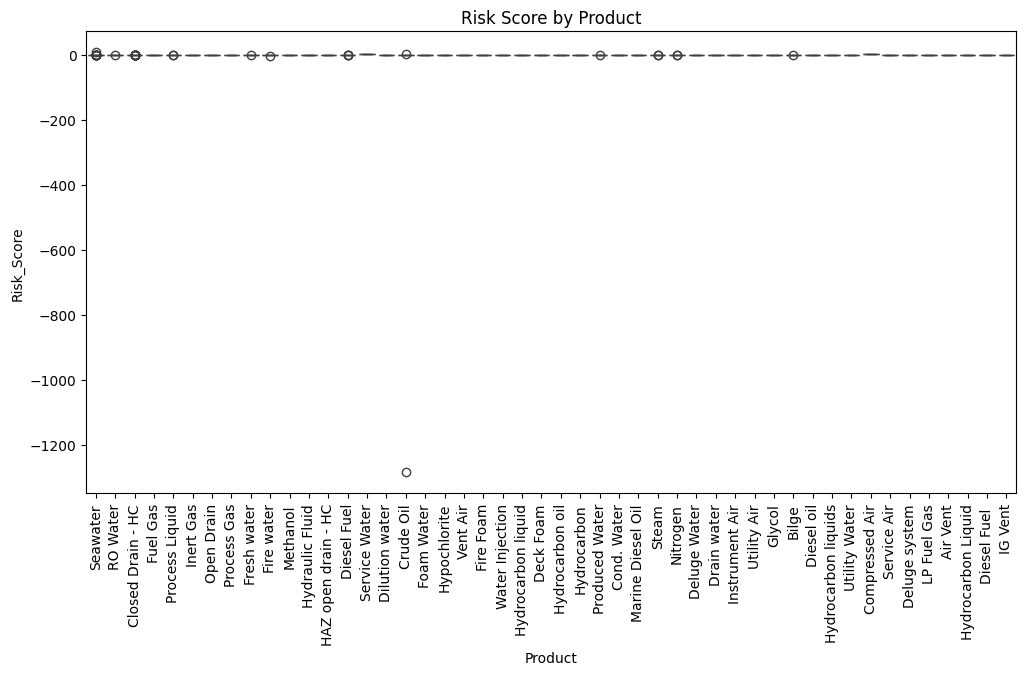

In [197]:
plt.figure(figsize=(12,6))
sns.boxplot(x="Product", y="Risk_Score", data=df_original)
plt.xticks(rotation=90)
plt.title("Risk Score by Product")
plt.show()

### Risk Evolution Over Time

<Axes: xlabel='Exposure_Years', ylabel='Risk_Score'>

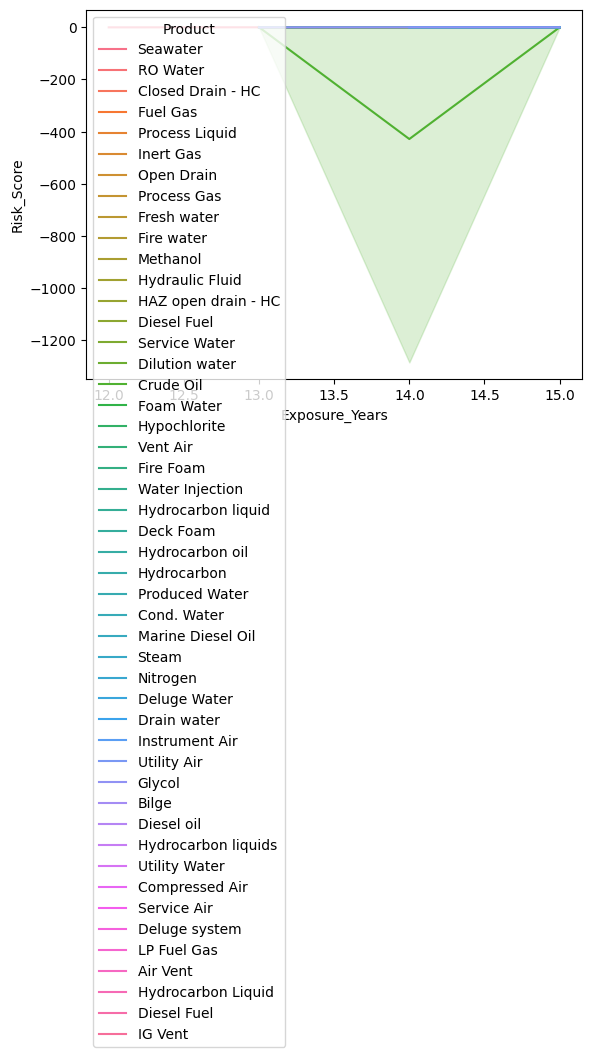

In [198]:
sns.lineplot(
    data=df_original,
    x="Exposure_Years",
    y="Risk_Score",
    hue="Product"
)

### Failure Timeline Insight

In [105]:
df_original['Pred_RUL'] = df['Pred_RUL']
df_original['Corrosion_Rate'] = df['Corrosion_Rate']

<Axes: xlabel='Pred_RUL', ylabel='Corrosion_Rate'>

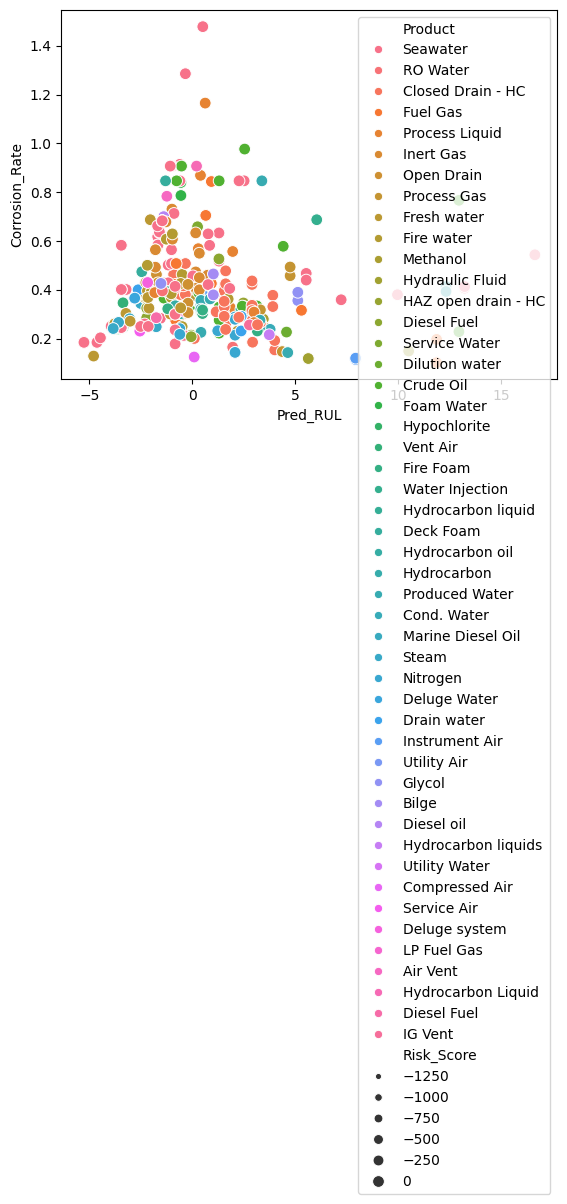

In [107]:
sns.scatterplot(
    data=df_original,
    x="Pred_RUL",
    y="Corrosion_Rate",
    hue="Product",
    size="Risk_Score"
)